In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from google.colab import files
from scipy.io import arff

In [ ]:
uploaded = files.upload()

Saving column_2C.dat to column_2C.dat
Saving column_3C.dat to column_3C.dat


In [ ]:
data = []
for fn in uploaded.keys():
  print('User uploaded file "{name}" of length {length} bytes'.format(
      name = fn, length = len(uploaded[fn])))
  data.append(fn)

User uploaded file "column_2C.dat" of length 11796 bytes
User uploaded file "column_3C.dat" of length 11796 bytes
['column_2C.dat', 'column_3C.dat']


In [ ]:
df1 = pd.read_csv(data[0])
df2 = pd.read_csv(data[1])
df1.head(3)

,63.03 22.55 39.61 40.48 98.67 -0.25 DH
0,39.06 10.06 25.02 29 114.41 4.56 DH
1,68.83 22.22 50.09 46.61 105.99 -3.53 DH
2,69.3 24.65 44.31 44.64 101.87 11.21 DH


In [ ]:
df2.head(3)

,63.03 22.55 39.61 40.48 98.67 -0.25 DH
0,39.06 10.06 25.02 29 114.41 4.56 DH
1,68.83 22.22 50.09 46.61 105.99 -3.53 DH
2,69.3 24.65 44.31 44.64 101.87 11.21 DH


In [ ]:
raw_data = arff.loadarff('column_2C_weka.arff')
df3 = pd.DataFrame(raw_data[0])
df3.head(3)

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,b'Abnormal'
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,b'Abnormal'
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,b'Abnormal'


In [ ]:
raw_data = arff.loadarff('column_3C_weka.arff')
df4 = pd.DataFrame(raw_data[0])
df4.head(3)

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,b'Hernia'
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,b'Hernia'
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,b'Hernia'


In [ ]:
variables = df3.columns.tolist()
print(variables)

['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis', 'class']


In [ ]:
independent_vars = []
for i in range(len(variables) - 1):
  independent_vars.append(variables[i])
print(independent_vars)

['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis']


In [ ]:
dependent_var = variables[len(variables) - 1]
print(dependent_var)

class


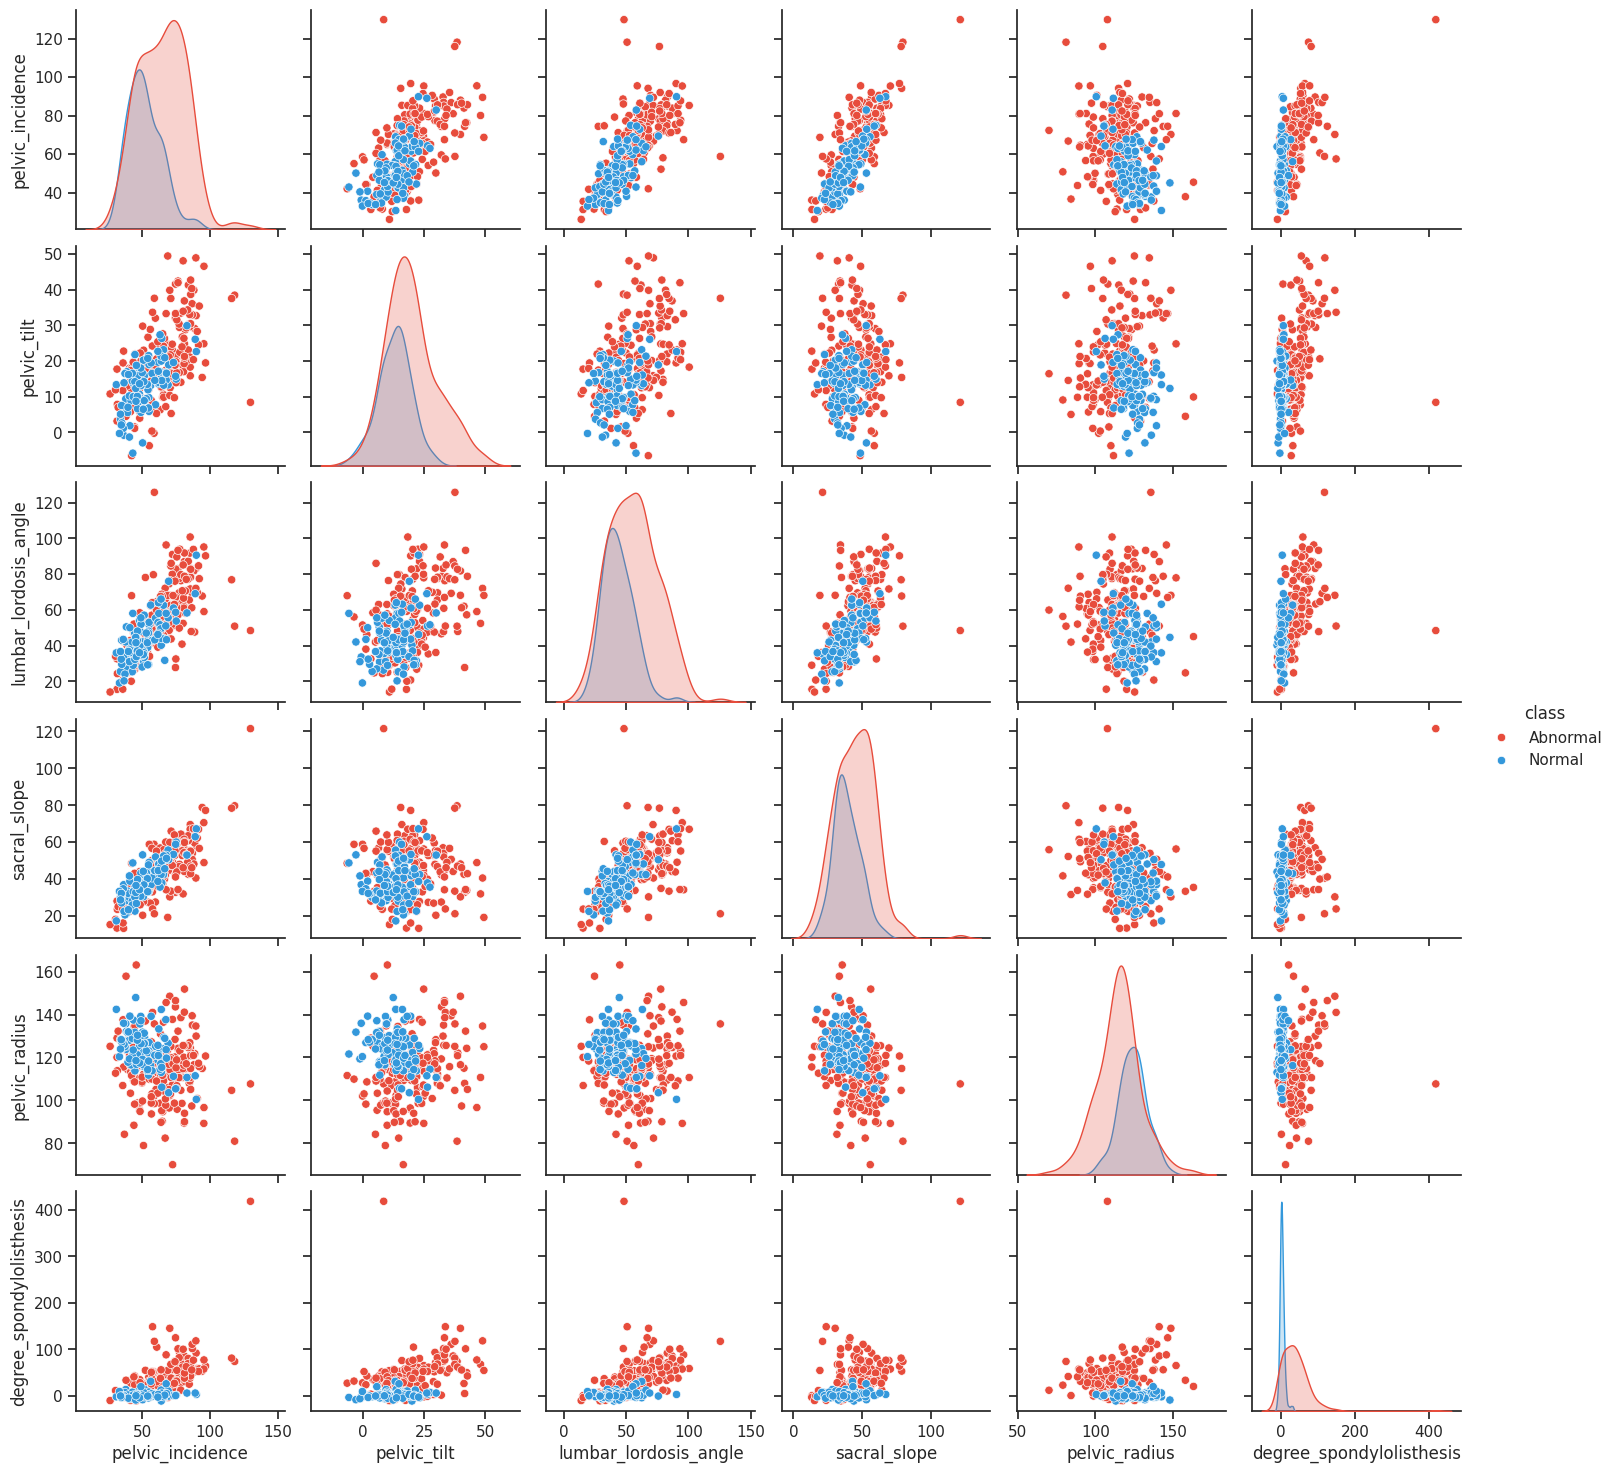

In [ ]:
custom = {"Abnormal": "#E74C3C", "Normal": "#3498DB"}
sns.pairplot(df3, hue=str(dependent_var), palette=custom, diag_kind='kde')
plt.show()

/tmp/ipython-input-4282133445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)


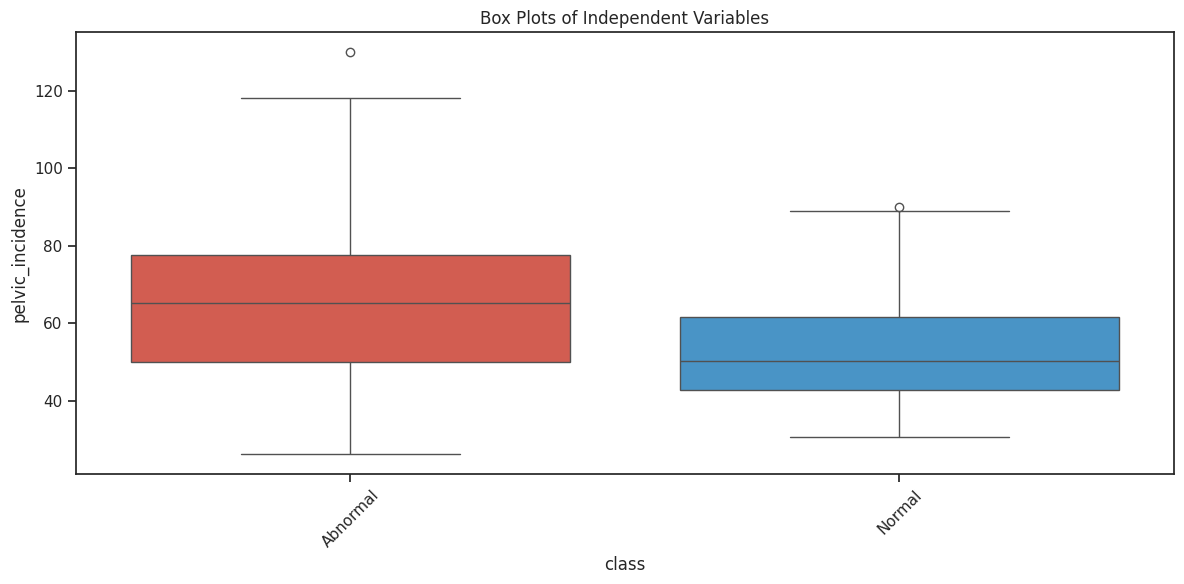

/tmp/ipython-input-4282133445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)


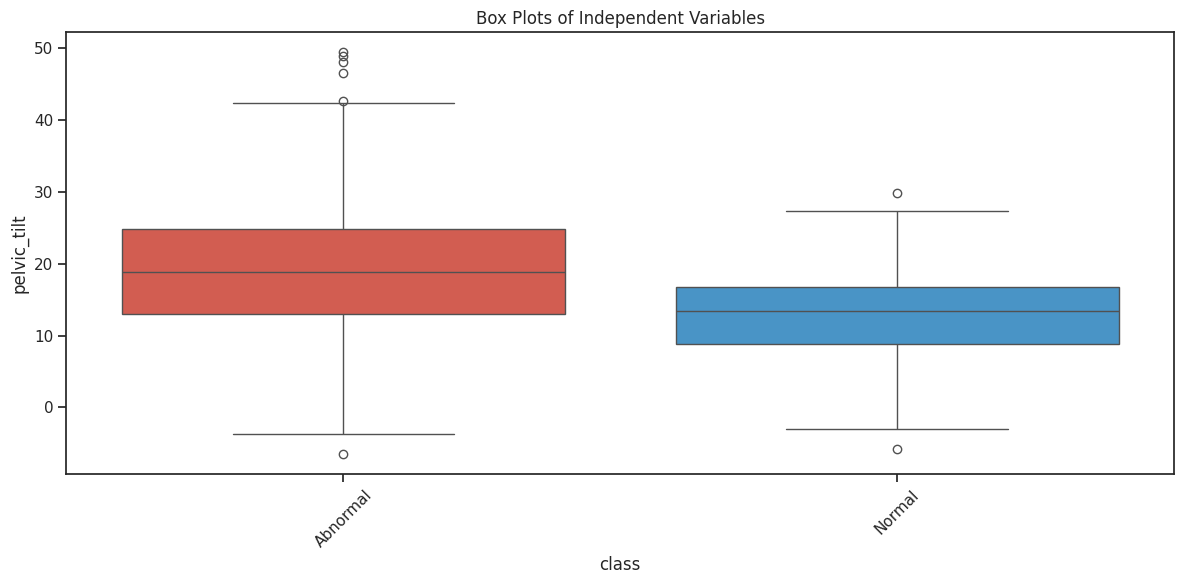

/tmp/ipython-input-4282133445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)


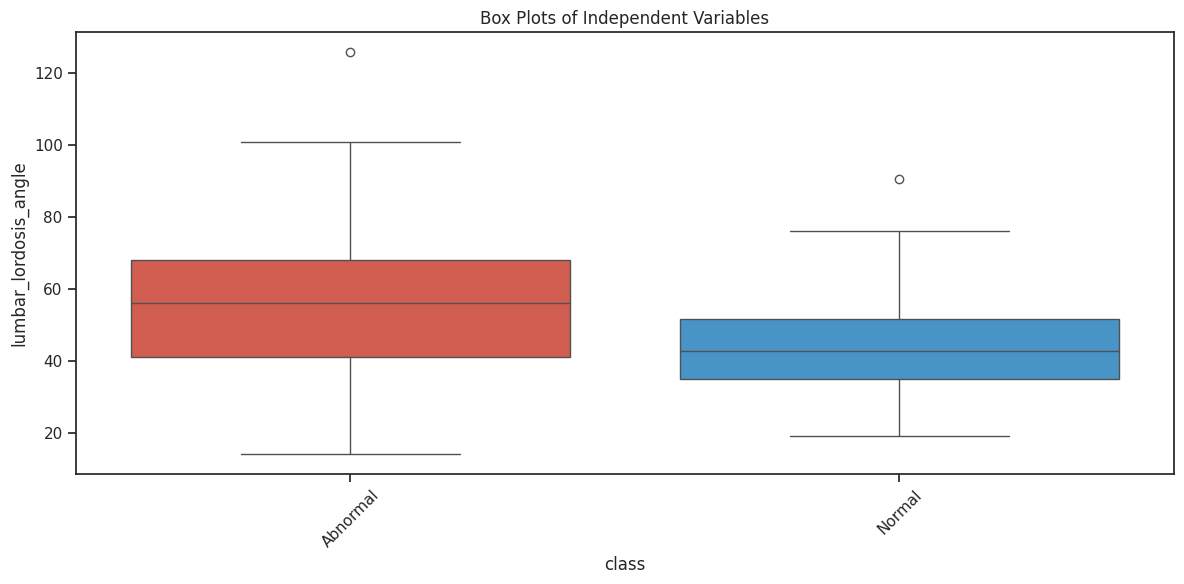

/tmp/ipython-input-4282133445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)


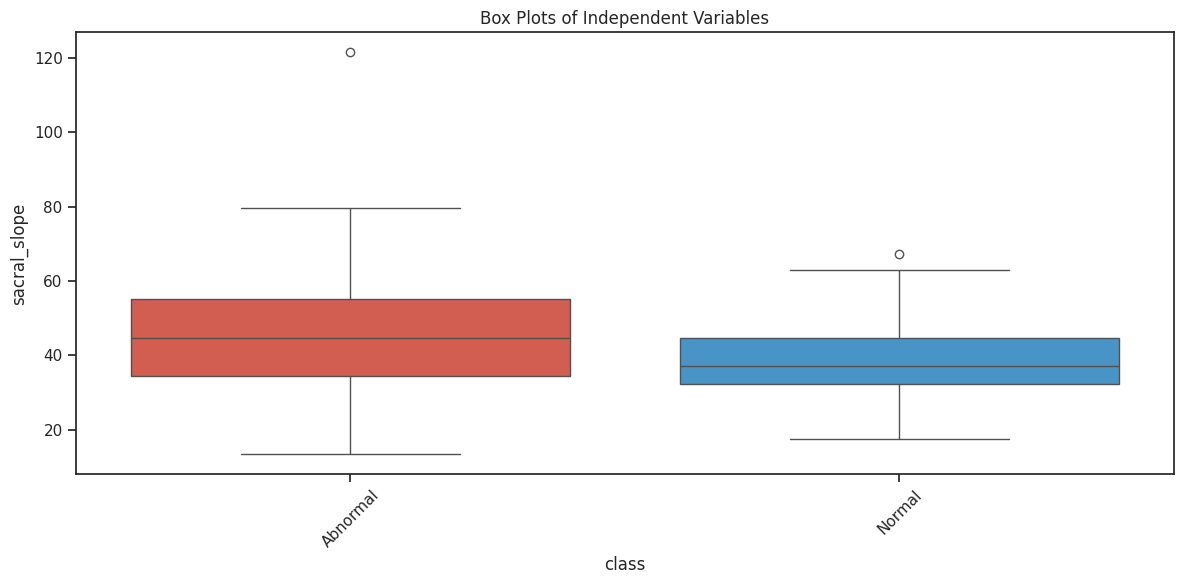

/tmp/ipython-input-4282133445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)


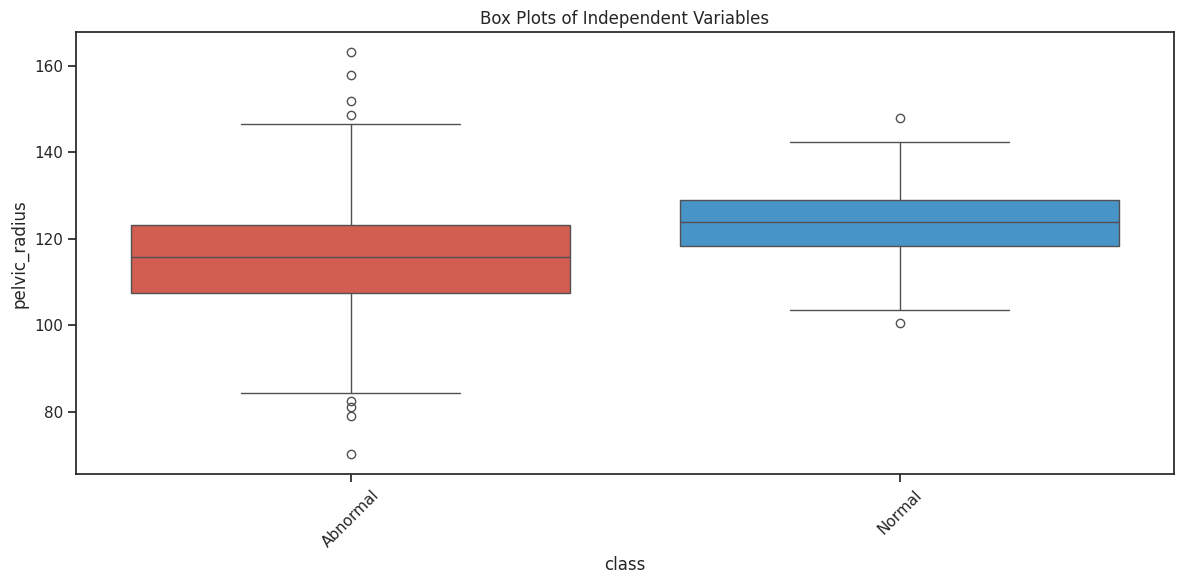

/tmp/ipython-input-4282133445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)


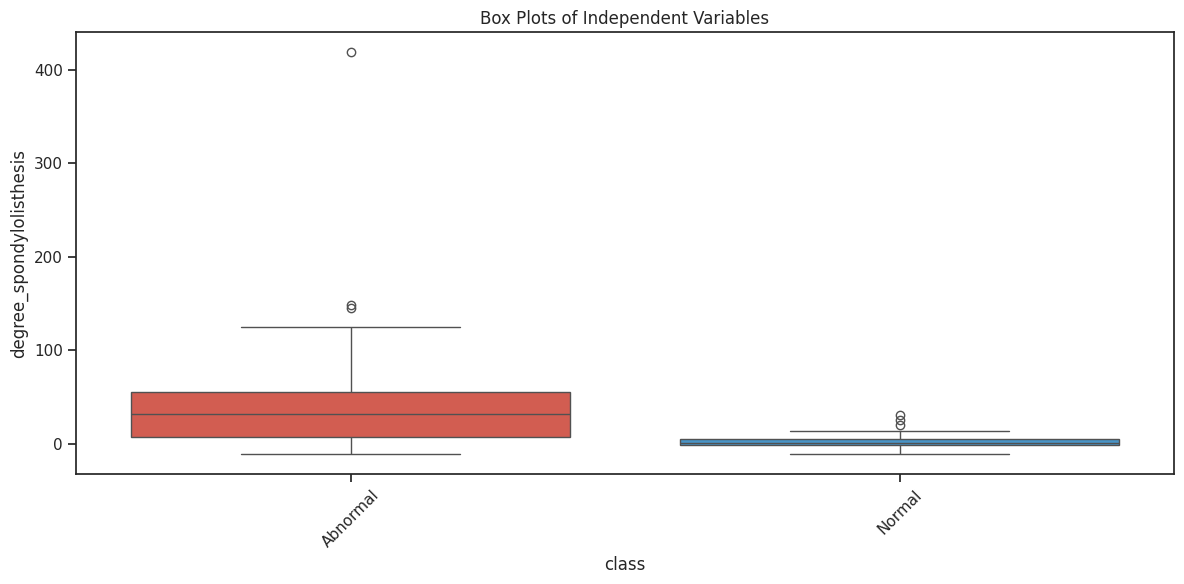

In [ ]:
for i in independent_vars:
  plt.figure(figsize=(12, 6))
  sns.boxplot(x=str(dependent_var), y=str(i), data=df3, palette=custom)
  plt.xticks(rotation=45)
  plt.title('Box Plots of Independent Variables')
  plt.tight_layout()
  plt.show()

In [ ]:
print(df3['class'].value_counts())

class
Abnormal    210
Normal      100
Name: count, dtype: int64


In [ ]:
df_train = pd.concat([df3.loc[df3['class'] == 'Normal'].head(70), df3.loc[df3['class'] == 'Abnormal'].head(140)])
df_train['class'].value_counts()

,count
class,
Abnormal,140
Normal,70


In [ ]:
test = df3.loc[df3['class'] == 'Normal'].iloc[70:]
test2 = df3.loc[df3['class'] == 'Abnormal'].iloc[140:]
df_test = pd.concat([test, test2])
df_test['class'].value_counts()

,count
class,
Abnormal,70
Normal,30


In [ ]:
# K Nearest Neigbor with Euclidean Metric
def knn():
